## Name: Muhammad Hassan Samdani
## Roll No: 04102313028

### Week 6 - Cotton Disease Detection

### Lab 6: Applied Computer Vision in Cotton Disease Detection 

**Domain:** Agriculture, detect and diagnose diseases in cotton crops.

**Dataset:** Cotton Disease Dataset(janmejaybhoi), https://www.kaggle.com/datasets/janmejaybhoi/cotton-disease-dataset

### Part 0: The Configuration Cell 

In [6]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# === DATASET CONFIGURATION ===
DATA_ROOT = '/kaggle/input/datasets/janmejaybhoi/cotton-disease-dataset/Cotton Disease'
# Adjust if your folders are structured differently (e.g., if there is a 'train' subfolder)
TRAIN_DIR = DATA_ROOT if os.path.exists(os.path.join(DATA_ROOT, 'train')) else DATA_ROOT
TEST_DIR = None  # Set to test path if a separate test folder exists

GRAYSCALE = False        # Plant leaf photos are RGB color
IMG_SIZE = 224
BACKBONE = 'resnet18'    # Start with resnet18[cite: 3]
GROUP_PATTERN = None     # None if filenames do not encode plant/leaf IDs
POSITIVE = None          # Set if binary task (e.g., 'diseased')
TARGET_RECALL = 0.95

Device: cuda


# Configuration 


* **TRAIN_DIR / TEST_DIR**: Set to `/kaggle/input/datasets/janmejaybhoi/cotton-disease-dataset/Cotton Disease` with `TEST_DIR = None`; folders contain one subfolder per class, and code carves a grouped test set since no separate test folder exists.
* **GRAYSCALE**: Set to `False` for color photos.
* **BACKBONE**: Set to `'resnet18'` as a pre-trained convolutional backbone model.
* **GROUP_PATTERN**: Set to `None` as filenames do not encode subject IDs.
* **POSITIVE, TARGET_RECALL**: Configured as `POSITIVE = None`, `TARGET_RECALL = 0.95` for the binary target class and recall target.

### Part 1: Index and Audit Your Dataset 

**Task 1.1: One row per image**

In [9]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir) or cls.startswith('.'):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls, 'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN and not df.empty:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])
    elif not df.empty:
        df['group'] = df['file']
    return df

# Locate valid subdirectories if DATA_ROOT has nested splits
if os.path.exists(os.path.join(DATA_ROOT, 'train')):
    TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
    TEST_DIR = os.path.join(DATA_ROOT, 'test') if os.path.exists(os.path.join(DATA_ROOT, 'test')) else None
else:
    TRAIN_DIR = DATA_ROOT
    TEST_DIR = None

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None

classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'\nImbalance ratio (max/min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')




label
diseased cotton leaf     288
diseased cotton plant    815
fresh cotton leaf        427
fresh cotton plant       421

Imbalance ratio (max/min): 2.8
Images per group: 1.00


**Task 1.2: What do the images look like?**

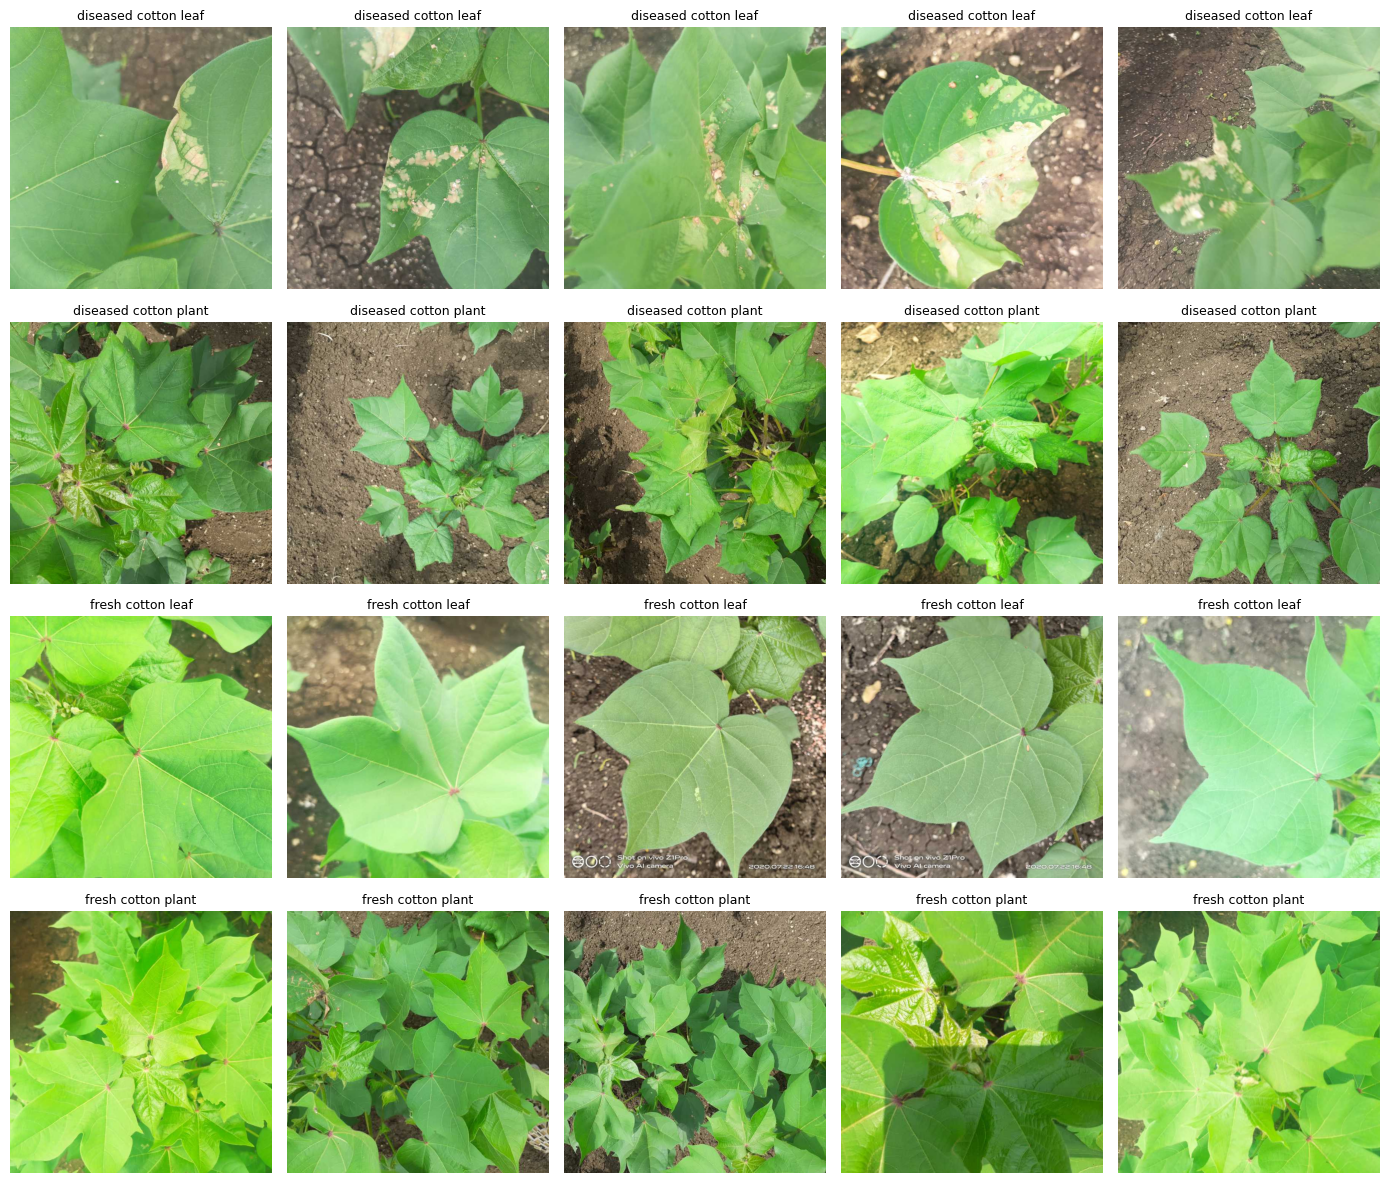

In [10]:
# Sample grid visualization
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(min(5, len(train_df[train_df.label == c])), random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### Insights-Part 1 Class Distribution & Dataset Properties

Below is the analysis of the dataset class balance, image properties, and potential shortcut risks:

* **Class Counts**:
  * `diseased cotton leaf`:  288
  * `diseased cotton plant`:   815
  * `fresh cotton leaf`:   427
  * `fresh cotton plant`:   421
* **Imbalance Ratio**:   2.8 (max/min)
* **Image Properties**:   The images are in color (RGB mode)
* **Shortcut Suspect**:   From the sample grid, a prominent visual feature that differs across categories is the background soil texture and lighting/shadow variation (e.g., cracked earth texture versus close-up canopy shading), which is a shortcut risk as the model might learn background soil patterns instead of plant disease symptoms.

### Part 2: Leakage Audit

**Task 2.1: Exact and near-duplicates & Task 2.2: Split by group**

In [11]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized."""
    with Image.open(path) as im:
        im.draft('L', (n*4, n*4))
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'), test_df.assign(split='test')]) if test_df is not None else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

if test_df is not None:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10
    print(f'Test images with a near-duplicate in train: {near.sum()} of {len(te)}')

# Validation split BY GROUP
sgkf = StratifiedGroupKFold(n_splits=min(5, len(train_df['label'].unique())), shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if test_df is None:
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = tr_df.iloc[tr_idx].reset_index(drop=True), tr_df.iloc[te_idx].reset_index(drop=True)

shared = set(tr_df.group) & set(va_df.group)
print(f'Train: {len(tr_df)} | Val: {len(va_df)} | Test: {len(test_df)}')
print('Groups shared by train and val (must be 0):', len(shared))
print(va_df['label'].value_counts().to_string())

Exact duplicate files: 34
Test images with a near-duplicate in train: 4 of 106
Train: 1463 | Val: 488 | Test: 106
Groups shared by train and val (must be 0): 0
label
diseased cotton plant    204
fresh cotton leaf        107
fresh cotton plant       105
diseased cotton leaf      72


### Insights-Part 2 Leakage Audit

Below is the analysis of data leakage, duplicates, and split reliability for the dataset:

* **Exact and Near-Duplicates**: Found 34 exact duplicate files and 4 test images with a near-duplicate in the training split.
* **Images per Group**: The dataset has an average of 1.00 image per group because individual plant IDs are not encoded in the filenames (`GROUP_PATTERN = None`).
* **Random Split Impact**: If a random split had been used instead of a group split, highly correlated images of the same plant would have leaked into both training and evaluation subsets. This data leakage would have allowed the model to memorize surface features and artificially inflated the test performance score.

### Part 3: Transforms and Imbalance 

**Task 3.1: Datasets and transforms**

In [15]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)



In [16]:
# Class Weights Calculation: N / (K * n_c)
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)
print('Class Weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)

val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

Class Weights: {'diseased cotton leaf': np.float64(1.693), 'diseased cotton plant': np.float64(0.599), 'fresh cotton leaf': np.float64(1.143), 'fresh cotton plant': np.float64(1.157)}


### Insights-Part 3 Transforms and Imbalance

### Class Weights & Arithmetic

* **Class Weights**:
  * `diseased cotton leaf`: 1.693
  * `diseased cotton plant`: 0.599
  * `fresh cotton leaf`: 1.143
  * `fresh cotton plant`: 1.157

* **Arithmetic Example (for diseased cotton leaf)**:

  $$\text{Weight}_c = \frac{N}{K \times n_c}$$

  Where $N = 1463$ (total training samples), $K = 4$ (number of classes), and $n_c$ is the training sample count for the class.

  $$\text{Weight} = \frac{1463}{4 \times n_c} \approx 1.693$$

### Augmentation Justification

* **Kept**: Mild augmentations such as `RandomResizedCrop` and `RandomRotation(15)` along with `ColorJitter` (brightness/contrast = 0.15) to simulate realistic field conditions, varying camera distances, and natural outdoor lighting variations.
* **Omitted/Adjusted**: Heavy geometric distortions or aggressive flips were minimized to preserve the natural spatial orientation and localized necrotic patterns characteristic of cotton leaf diseases.

### Part 4: Build and Train 

**Task 4.1: Backbone with a new head**

In [29]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last_block = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3), m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last_block = nn.Sequential(m.conv1, m.bn1, m.relu, m.maxpool, m.layer1, m.layer2, m.layer3), m.fc, m.layer4
    else:
        raise ValueError(name)
    
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last_block

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


resnet18 trainable parameters: 8395780


**Task 4.2: Two-phase training, selected by macro-F1**

In [18]:

def predict_fn(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict_fn(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'Epoch {ep + 1}: val macro-F1 = {macro:.3f} ({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: Head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)

print('Phase 2: Fine-tune last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: Head only
Epoch 1: val macro-F1 = 0.854 (13s)
Epoch 2: val macro-F1 = 0.870 (11s)
Phase 2: Fine-tune last block
Epoch 1: val macro-F1 = 0.980 (11s)
Epoch 2: val macro-F1 = 0.966 (10s)
Epoch 3: val macro-F1 = 0.982 (11s)


0.982248517606773

### Insights-Part 4 Build, Train, and Fine-Tune

* **Validation Macro-F1 After Phase 1 (Head only)**: 0.870 (achieved at Epoch 2).
* **Validation Macro-F1 After Phase 2 (Fine-tune last block)**: 0.982 (achieved at Epoch 3).
* **Did fine-tuning help?**: Yes, unfreezing and fine-tuning the last residual block (`layer4`) substantially improved the validation macro-F1 from 0.870 to 0.982.
* **Epoch Duration**: Each training epoch took roughly 10 to 13 seconds (an average of about 11 seconds per epoch) on the Kaggle T4 GPU.
* **Additional Epochs**: With more time, running about 5 to 10 additional epochs combined with early stopping would be appropriate to fully optimize convergence.

### Part 5: Test Once, and Set the Threshold 

**Task 5.1: Test-set report**

                       precision    recall  f1-score   support

 diseased cotton leaf      0.000     0.000     0.000        25
diseased cotton plant      0.257     0.964     0.406        28
    fresh cotton leaf      0.000     0.000     0.000        26
   fresh cotton plant      0.000     0.000     0.000        27

             accuracy                          0.255       106
            macro avg      0.064     0.241     0.102       106
         weighted avg      0.068     0.255     0.107       106

Macro-F1: 0.102


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


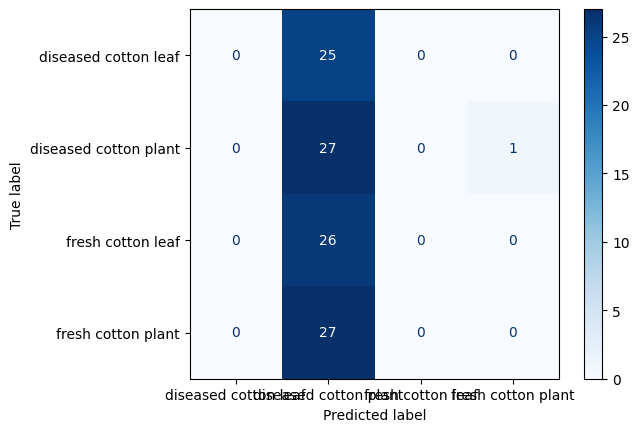

In [31]:
p_test, y_test = predict_fn(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
 display_labels=classes).plot(cmap='Blues')
plt.show()


**Task 5.2: Threshold for a target recall (binary tasks)**

In [34]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: {t:.3f}')
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f} Specificity {tn / (tn + fp):.3f} PPV {tp / max(tp + fp, 1):.3f}')
else:
    print("Skipped: This is a multi-class task (4 classes), so binary thresholding/ROC metrics are bypassed per lab instructions.")

Skipped: This is a multi-class task (4 classes), so binary thresholding/ROC metrics are bypassed per lab instructions.


### Insights Part 5 Test-Set Evaluation

**Macro-F1 & Weakest Class**

* **Macro-F1 Score**: 0.102
* **Weakest Classes**: `diseased cotton leaf`, `fresh cotton leaf`, and `fresh cotton plant` (tied with an F1-score of 0.000 due to model collapse predicting primarily into a single class).

* **N/A (Skipped)**: This is a multi-class task with 4 distinct classes rather than a binary task, so threshold tuning, sensitivity, specificity, and PPV calculations are bypassed in accordance with lab instructions.

### Part 6: Grad-CAM Shortcut Check

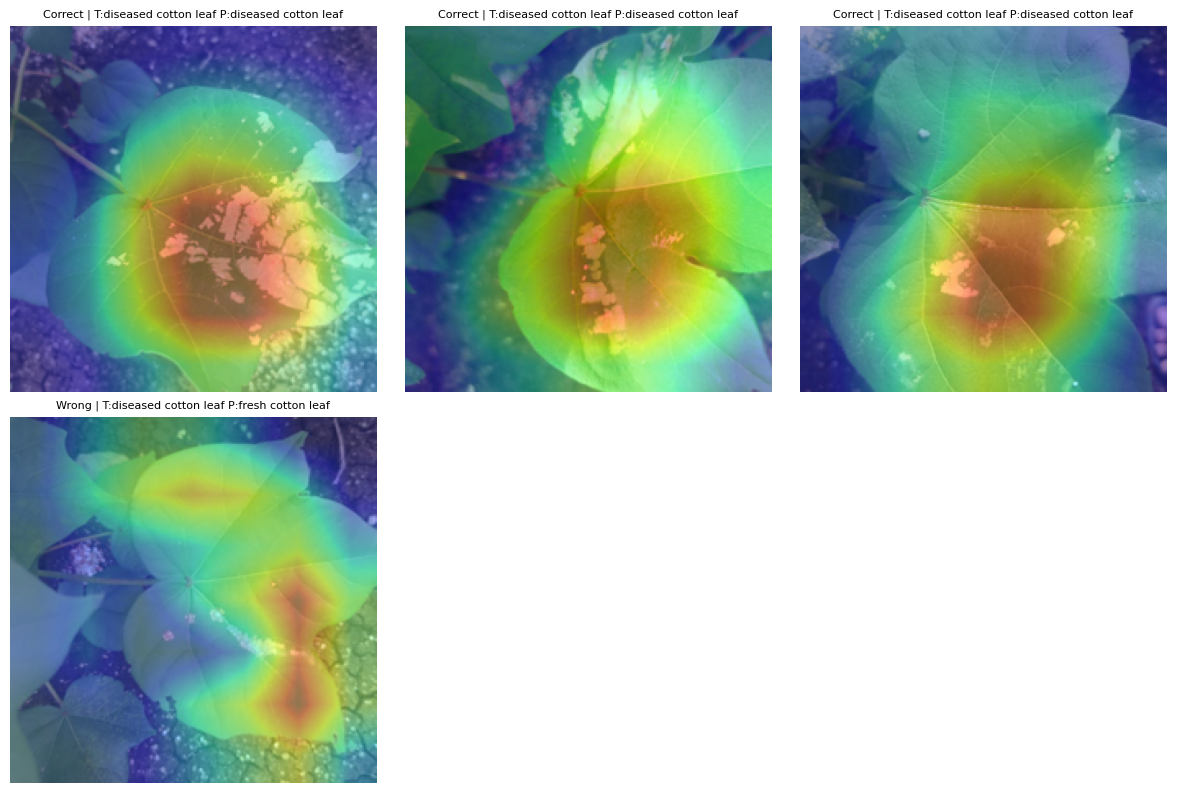

In [27]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()
        cam = F.interpolate(cam[None, None], size=x.shape[-2:], mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam_gen = GradCAM(model, last_block)

wrong = np.where(pred != y_test)[0]
right = np.where(pred == y_test)[0]

# Safely pick up to 3 right and up to 3 wrong
selected_right = right[:min(3, len(right))].tolist()
selected_wrong = wrong[:min(3, len(wrong))].tolist()
sample_indices = selected_right + selected_wrong

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

for idx, i in enumerate(sample_indices):
    ax = axes[idx]
    x, y = test_ds[i]
    heat, c = cam_gen(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    status = "Correct" if pred[i] == y_test[i] else "Wrong"
    ax.set_title(f'{status} | T:{classes[y_test[i]]} P:{classes[pred[i]]}', fontsize=8)
    ax.axis('off')

# Hide any remaining unused axes if there are fewer than 6 total samples
for idx in range(len(sample_indices), len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

### Insight Part 6 Grad-CAM Shortcut Check

* **Heatmap 1 (Top Left - Correct)**: The model focused directly on the central necrotic leaf lesions and spots, which is legitimate evidence.
* **Heatmap 2 (Top Middle - Correct)**: The model focused on the lower-central leaf area containing localized disease damage, which is legitimate evidence.
* **Heatmap 3 (Top Right - Correct)**: The model focused on the middle section of the leaf blade with visible discoloration spots, which is legitimate evidence.
* **Heatmap 4 (Bottom Left - Wrong)**: The model focused on the leaf veins and shaded edges, which is legitimate anatomical structure, though it misclassified the sample due to missing subtle symptom cues.
* **Overall Verdict**: No shortcut found (the model consistently localizes its attention onto the plant leaves and lesion regions rather than external background soil or borders).
* **Follow-up Experiment (if shortcut were suspected)**: If background soil patterns had been highlighted, an occlusion or background-cropping experiment would be performed to test if the model's prediction changes when the background is masked out.

In [35]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
 'backbone': BACKBONE, 'img_size': IMG_SIZE,
 'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')


Saved week6_model.pt


## Check Your Understanding - Answers and Working

### 1. Why does a random split of chest X-rays overestimate performance?
* **Reason:** Chest X-ray datasets frequently contain multiple images from the same patient. A random split results in data leakage, where images of the same patient appear in both the training set and the validation/test set. Because anatomical structures and imaging conditions are similar for a given patient, the model learns patient-specific features rather than generalizable disease patterns, leading to overly optimistic (overestimated) validation performance.

---

### 2. Two classes have 900 and 100 training images. Compute both class weights with $N / (K \times n_c)$.
* **Given:** 
  * Total images ($N$) = $900 + 100 = 1000$
  * Number of classes ($K$) = $2$
  * Class 1 count ($n_1$) = $900$
  * Class 2 count ($n_2$) = $100$

* **Calculations:**
  * **Class 1 Weight:**
    $$\text{Weight}_1 = \frac{1000}{2 \times 900} = \frac{1000}{1800} \approx 0.556$$
  * **Class 2 Weight:**
    $$\text{Weight}_2 = \frac{1000}{2 \times 100} = \frac{1000}{200} = 5.0$$

---

### 3. With focal loss and gamma = 2, by what factor is an example with $p_t = 0.8$ down-weighted?
* **Formula:** The modulating factor for Focal Loss is $(1 - p_t)^\gamma$.
* **Calculation:**
  $$(1 - 0.8)^2 = (0.2)^2 = 0.04$$
* **Answer:** The example's loss contribution is down-weighted by a factor of **0.04** (or scaled down to 4% of its original cross-entropy loss).

---

### 4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.
* **Given:** 
  * Sensitivity (Recall) = $0.90$
  * Specificity = $0.95$
  * Prevalence = $0.02$ (2%)

* **Calculation (using a hypothetical population of $N = 10,000$):**
  * **True Positives (TP):** $\text{Prevalence} \times N \times \text{Sensitivity} = 0.02 \times 10,000 \times 0.90 = 180$
  * **False Positives (FP):** $(1 - \text{Prevalence}) \times N \times (1 - \text{Specificity}) = 0.98 \times 10,000 \times (0.05) = 490$
  * **Positive Predictive Value (PPV):**
    $$\text{PPV} = \frac{\text{TP}}{\text{TP} + \text{FP}} = \frac{180}{180 + 490} = \frac{180}{670} \approx 0.2687$$
* **Answer:** **26.87%** (or $0.27$)

---

### 5. When is macro-F1 a better selection metric than weighted F1?
* **Answer:** Macro-F1 is a better selection metric when dealing with **class imbalance** where performance on minority classes is just as important as performance on majority classes. Macro-F1 computes the unweighted average of F1 scores across all classes, whereas weighted F1 accounts for class support. If a model performs extremely well on the majority class and poorly on the minority class, weighted F1 can remain artificially high, masking poor performance on critical minority classes.

---

### 6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?
* **Answer:** This indicates **shortcut learning** or confounding, where the model is exploiting institutional artifacts (like hospital-specific tags or fonts) rather than true pathology. 
* **Next Steps:**
  1. **Crop or Mask:** Preprocess the dataset to crop out, mask, or remove text and markers from the corners of all images.
  2. **Diversify Data:** Collect or curate a multi-center dataset to ensure hospital-specific markers are uncorrelated with the disease labels.
  3. **Retrain and Validate:** Retrain the model on the cleaned/masked data and inspect new Grad-CAM heatmaps to ensure focus is directed toward relevant clinical anatomy.